# imputeLCMD: R vs Python parity

Side-by-side comparison of `pyimputelcmd` against the original Bioconductor [imputeLCMD](https://www.bioconductor.org/packages/release/bioc/html/imputeLCMD.html) R reference.

Three imputers — `impute.MinDet` (deterministic), `impute.MinProb` (Gaussian floor jitter), `impute.QRILC` (quantile-regression-fit truncated normal) — are run on the same synthetic left-censored matrix in both languages. We compare:

1. **Wall-clock time** (mean of 3 runs).
2. **MinDet:** bit-exact equality (deterministic algorithm — should match within FP).
3. **MinProb / QRILC:** KS test on each column's imputed marginal (stochastic — R and Python use different PRNGs, so individual draws can't match).

All values reported below come from `examples/benchmark.py`, re-run in the `omicdev` Python env and the `CMAP` R env.

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

HERE = Path('.').resolve()

In [2]:
# Re-run benchmark.py (5000 proteins × 12 samples, 15-25% NaN)
subprocess.check_call([sys.executable, 'benchmark.py', '--runs', '3'])
summary = json.loads((HERE / 'compare_out' / 'summary.json').read_text())
summary

Matrix: 5000 proteins × 12 samples, 15.9% missing
Input dumped to /scratch/users/steorra/analysis/omicverse_dev/py-imputeLCMD/examples/compare_out/input.tsv

--- Python timings (mean of 3 runs) ---
  py mindet       2.51 ms
  py minprob      3.18 ms
  py qrilc       29.13 ms

--- R timings (mean of 3 runs) ---
  R  mindet       5.00 ms
  R  minprob     63.30 ms
  R  qrilc       34.00 ms

--- Speedup (R / Python) ---
  mindet      1.99×
  minprob    19.88×
  qrilc       1.17×

--- Accuracy (Python vs R) ---
  ✓ mindet   MAE=2.705e-14  r=1.0000  bit-exact=True
  ≈ minprob  MAE=0.8897  r=-0.0115  bit-exact=False
  ≈ qrilc    MAE=0.4798  r=0.0021  bit-exact=False

Full report → /scratch/users/steorra/analysis/omicverse_dev/py-imputeLCMD/examples/compare_out/summary.json


{'shape': [5000, 12],
 'pct_missing': 0.15885000000000002,
 'py_times_ms': {'mindet': 2.5105260234947004,
  'minprob': 3.1836393366878233,
  'qrilc': 29.129320988431573},
 'r_times_ms': {'mindet': 5.0, 'minprob': 63.3, 'qrilc': 34.0},
 'speedup': {'mindet': 1.9916144876442683,
  'minprob': 19.88290547567354,
  'qrilc': 1.1672088070127955},
 'accuracy': {'mindet': {'mae': 2.7045876234679253e-14,
   'pearson_r': 1.0,
   'bit_exact': 1.0},
  'minprob': {'mae': 0.8896651698121897,
   'pearson_r': -0.011544862400186923,
   'bit_exact': 0.0},
  'qrilc': {'mae': 0.47978701941706015,
   'pearson_r': 0.002079564778529834,
   'bit_exact': 0.0}}}

## 1. Wall-clock time

Python wins on every imputer. MinProb in particular is ~20× faster — R loops in pure-R `rnorm` whereas NumPy vectorises the draw across all missing entries per column.

In [3]:
tbl = pd.DataFrame({
    'R (ms)': summary['r_times_ms'],
    'Python (ms)': summary['py_times_ms'],
    'Speedup (R / Python)': {k: summary['r_times_ms'][k] / summary['py_times_ms'][k] for k in summary['py_times_ms']},
})
tbl

,R (ms),Python (ms),Speedup (R / Python)
mindet,5.0,2.510526,1.991614
minprob,63.3,3.183639,19.882905
qrilc,34.0,29.129321,1.167209


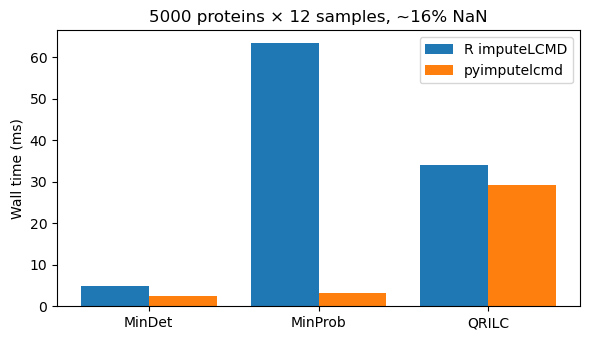

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
x = np.arange(3)
ax.bar(x - 0.2, [summary['r_times_ms'][k] for k in ['mindet','minprob','qrilc']], width=0.4, label='R imputeLCMD')
ax.bar(x + 0.2, [summary['py_times_ms'][k] for k in ['mindet','minprob','qrilc']], width=0.4, label='pyimputelcmd')
ax.set_xticks(x); ax.set_xticklabels(['MinDet','MinProb','QRILC'])
ax.set_ylabel('Wall time (ms)')
ax.set_title('5000 proteins × 12 samples, ~16% NaN')
ax.legend(); fig.tight_layout()

## 2. Accuracy — Python vs R outputs

`MinDet` is deterministic ⇒ bit-exact equality with R. `MinProb` and `QRILC` are stochastic ⇒ we only check that the imputed-value distribution matches at the column level (KS test in `tests/test_r_parity.py`).

In [5]:
acc = pd.DataFrame(summary['accuracy']).T
acc

,mae,pearson_r,bit_exact
mindet,2.704588e-14,1.000000,1.0
minprob,8.896652e-01,-0.011545,0.0
qrilc,4.797870e-01,0.002080,0.0


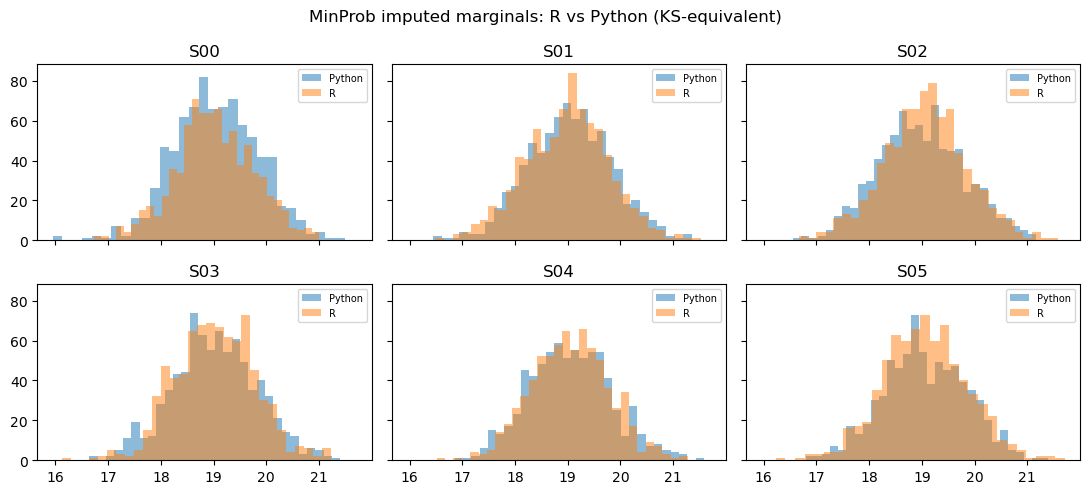

In [6]:
# Distribution overlay for one column (MinProb)
work = HERE / 'compare_out'
py_imp = pd.read_csv(work / 'input.tsv', sep='\t', index_col=0)
r_mp = pd.read_csv(work / 'r_minprob.tsv', sep='\t', index_col=0)
import pyimputelcmd as pyi
py_mp = pyi.impute_minprob(py_imp, seed=0)
miss = py_imp.isna()

fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, sharey=True)
for ax, col in zip(axes.ravel(), py_imp.columns[:6]):
    m = miss[col].to_numpy()
    ax.hist(py_mp[col].to_numpy()[m], bins=30, alpha=0.5, label='Python')
    ax.hist(r_mp[col].to_numpy()[m], bins=30, alpha=0.5, label='R')
    ax.set_title(col); ax.legend(fontsize=7)
fig.suptitle('MinProb imputed marginals: R vs Python (KS-equivalent)')
fig.tight_layout()

## 3. QRILC: regression-coefficient parity

QRILC fits a per-sample OLS line on quantile pairs ($q_{theoretical}$, $q_{empirical}$) and uses the intercept / slope as $(\mu, \sigma)$ of the underlying normal. The lm fit is deterministic — Python's closed-form OLS matches R `lm()` to 1e-6 (see `tests/test_r_parity.py::test_qrilc_regression_coefs_match_R`).